<a href="https://colab.research.google.com/github/csnorbi18/Projekt/blob/master/BPI_Challenge_2017.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
#%pip install -q -U pm4py r4pm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 27.4 MB/s eta 0:00:00


In [36]:
from pathlib import Path
import pandas as pd
import pm4py
import gzip
import shutil
import os
import matplotlib.pyplot as plt
import hashlib
from google.colab import files
pd.set_option("display.max_columns", 50)
import r4pm

In [8]:
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))
print("Feltöltött fájl:", filename)

Saving BPI Challenge 2017.xes.gz to BPI Challenge 2017.xes.gz
Feltöltött fájl: BPI Challenge 2017.xes.gz


In [9]:
if not Path(filename).is_file():
    raise FileNotFoundError(f"Nem található a fájl: {filename}")

# XES és tömörített XES fájlok kezelése
if filename.lower().endswith((".xes", ".xes.gz")):

    # A PM4Py közvetlenül támogatja a .xes.gz fájlokat
    log = pm4py.read_xes(filename)

    # Átalakítás DataFrame formátumra, ha szükséges
    if not isinstance(log, pd.DataFrame):
        log = pm4py.convert_to_dataframe(log)

    # Kötelező PM4Py-oszlopok
    required = [
        "case:concept:name",
        "concept:name",
        "time:timestamp"
    ]

    missing = [c for c in required if c not in log.columns]

    if missing:
        raise ValueError(
            "A XES fájlból hiányzó kötelező attribútum(ok): "
            + ", ".join(missing)
        )

    # Időbélyegek egységesítése
    log["time:timestamp"] = pd.to_datetime(
        log["time:timestamp"],
        utc=True
    )

    # Egységes PM4Py DataFrame-formátum
    log = pm4py.format_dataframe(
        log,
        case_id="case:concept:name",
        activity_key="concept:name",
        timestamp_key="time:timestamp"
    )

    print("XES eseménynapló sikeresen betöltve.")

else:
    raise ValueError("Csak .xes vagy .xes.gz fájl támogatott.")

# Rendezés esetszám és időbélyeg alapján
log = (
    log.sort_values(
        ["case:concept:name", "time:timestamp"],
        kind="stable"
    )
    .reset_index(drop=True)
)

/usr/local/lib/python3.13/dist-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


parsing log, completed traces ::   0%|          | 0/31509 [00:00<?, ?it/s]

XES eseménynapló sikeresen betöltve.


In [10]:
n_events = len(log)
n_cases = log["case:concept:name"].nunique()
n_activities = log["concept:name"].nunique()

print("Események száma:", n_events)
print("Esetek száma:", n_cases)
print("Tevékenységek száma:", n_activities)
print("Átlagos eseményszám esetenként:", round(n_events / n_cases, 2) if n_cases else None)

print("\nOszlopok:")
print(list(log.columns))
print("\nAdattípusok:")
print(log.dtypes)

log.head(3)

Események száma: 1202267
Esetek száma: 31509
Tevékenységek száma: 26
Átlagos eseményszám esetenként: 38.16

Oszlopok:
['Action', 'org:resource', 'concept:name', 'EventOrigin', 'EventID', 'lifecycle:transition', 'time:timestamp', 'case:LoanGoal', 'case:ApplicationType', 'case:concept:name', 'case:RequestedAmount', 'FirstWithdrawalAmount', 'NumberOfTerms', 'Accepted', 'MonthlyCost', 'Selected', 'CreditScore', 'OfferedAmount', 'OfferID', '@@index', '@@case_index']

Adattípusok:
Action                                object
org:resource                          object
concept:name                  string[python]
EventOrigin                           object
EventID                               object
lifecycle:transition                  object
time:timestamp           datetime64[ns, UTC]
case:LoanGoal                         object
case:ApplicationType                  object
case:concept:name             string[python]
case:RequestedAmount                 float64
FirstWithdrawalAmount    

,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,...,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID,@@index,@@case_index
0,Created,User_1,A_Create Application,Application,Application_1000086665,complete,2016-08-03 15:57:21.673000+00:00,"Other, see explanation",New credit,Application_1000086665,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
1,statechange,User_1,A_Submitted,Application,ApplState_161925113,complete,2016-08-03 15:57:21.734000+00:00,"Other, see explanation",New credit,Application_1000086665,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0
2,Created,User_1,W_Handle leads,Workflow,Workitem_747707399,schedule,2016-08-03 15:57:21.963000+00:00,"Other, see explanation",New credit,Application_1000086665,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,0


In [11]:
activities = pm4py.get_event_attribute_values(log, "concept:name")
activity_table = (
    pd.Series(activities, name="gyakoriság")
    .sort_values(ascending=False)
    .to_frame()
)
activity_table

,gyakoriság
W_Validate application,209496
W_Call after offers,191092
W_Call incomplete files,168529
W_Complete application,148900
W_Handle leads,47264
O_Create Offer,42995
O_Created,42995
O_Sent (mail and online),39707
A_Validating,38816
A_Accepted,31509


In [12]:
if "org:resource" in log.columns:
    resources = pm4py.get_event_attribute_values(log, "org:resource")
    resource_table = (
        pd.Series(resources, name="gyakoriság")
        .sort_values(ascending=False)
        .to_frame()
    )
    display(resource_table)

,gyakoriság
User_1,148404
User_3,26342
User_5,22900
User_87,22498
User_30,21272
...,...
User_146,23
User_145,10
User_148,4
User_147,2


In [13]:
start_activities = pm4py.get_start_activities(log)
end_activities = pm4py.get_end_activities(log)

print("Kezdőtevékenységek:")
display(pd.Series(start_activities, name="esetek száma").sort_values(ascending=False).to_frame())

print("\nVégtevékenységek:")
display(pd.Series(end_activities, name="esetek száma").sort_values(ascending=False).to_frame())

Kezdőtevékenységek:


,esetek száma
A_Create Application,31509



Végtevékenységek:


,esetek száma
W_Validate application,12662
W_Call after offers,9457
W_Call incomplete files,4676
O_Cancelled,4436
W_Complete application,144
W_Assess potential fraud,102
O_Sent (mail and online),15
O_Sent (online only),8
W_Shortened completion,5
W_Personal Loan collection,2


In [14]:
min_time = log["time:timestamp"].min()
max_time = log["time:timestamp"].max()

print("Első időbélyeg:", min_time)
print("Utolsó időbélyeg:", max_time)
print("Teljes időtartam:", max_time - min_time)

if "start:timestamp" in log.columns:
    print("Legkorábbi kezdési idő:", log["start:timestamp"].min())

Első időbélyeg: 2016-01-01 09:51:15.304000+00:00
Utolsó időbélyeg: 2017-02-01 14:11:03.499000+00:00
Teljes időtartam: 397 days 04:19:48.195000


In [15]:
variant_table = (
    log.sort_values(["case:concept:name", "time:timestamp"])
       .groupby("case:concept:name")["concept:name"]
       .apply(tuple)
       .value_counts()
       .rename_axis("variáns")
       .reset_index(name="esetek_száma")
)

print("Folyamatvariánsok száma:", len(variant_table))
display(variant_table.head(10))

Folyamatvariánsok száma: 15930


,variáns,esetek_száma
0,"(A_Create Application, A_Submitted, W_Handle l...",1056
1,"(A_Create Application, W_Complete application,...",1021
2,"(A_Create Application, A_Submitted, W_Handle l...",734
3,"(A_Create Application, A_Submitted, W_Handle l...",451
4,"(A_Create Application, A_Submitted, W_Handle l...",332
5,"(A_Create Application, A_Submitted, W_Handle l...",298
6,"(A_Create Application, W_Complete application,...",278
7,"(A_Create Application, A_Submitted, W_Handle l...",244
8,"(A_Create Application, A_Submitted, W_Handle l...",212
9,"(A_Create Application, A_Submitted, W_Handle l...",204


In [16]:
top_n = min(10, len(variant_table))
covered = variant_table.head(top_n)["esetek_száma"].sum()
coverage = covered / n_cases if n_cases else 0

print(f"A {top_n} leggyakoribb variáns az esetek {coverage:.1%}-át fedi le.")

A 10 leggyakoribb variáns az esetek 15.3%-át fedi le.


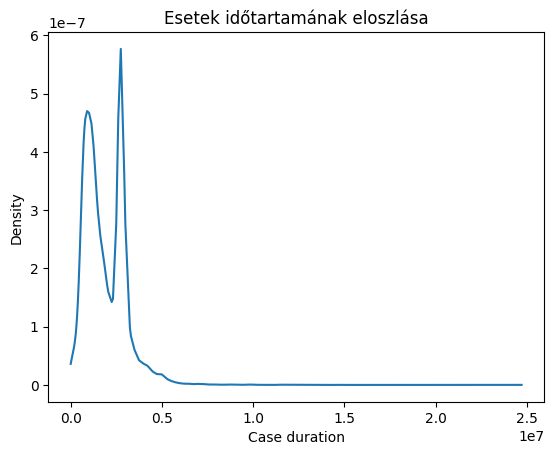

In [17]:
pm4py.view_case_duration_graph(
    log,
    graph_title="Esetek időtartamának eloszlása"
)

<Figure size 640x480 with 0 Axes>

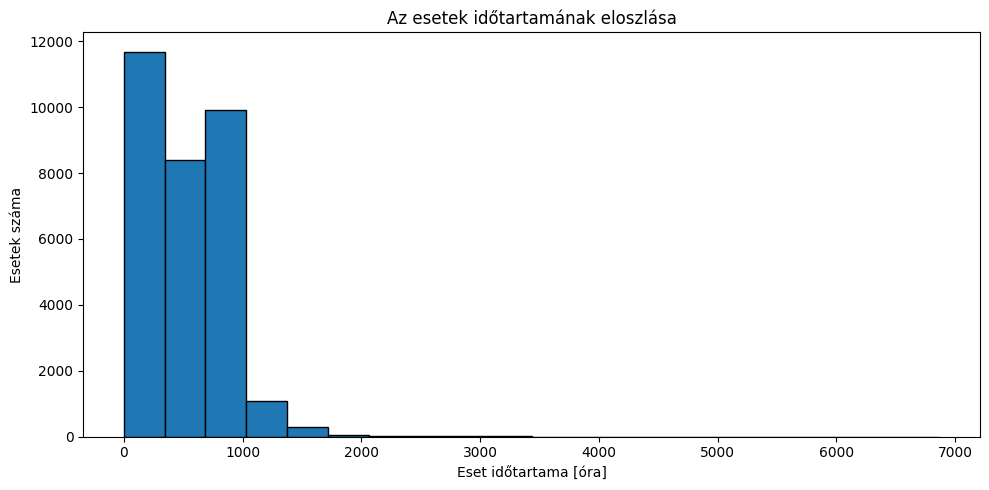

Esetek száma: 31509
Átlagos időtartam (óra): 525.59
Medián időtartam (óra): 458.11


In [21]:
# Esetek kezdő és befejező időpontjának meghatározása
case_times = log.groupby("case:concept:name")["time:timestamp"].agg(
    ["min", "max"]
)

# Esetek időtartama
case_duration = case_times["max"] - case_times["min"]

# Átváltás órára
case_duration_hours = case_duration.dt.total_seconds() / 3600

# Hisztogram
plt.figure(figsize=(10, 5))
plt.hist(case_duration_hours, bins=20, edgecolor="black")

plt.title("Az esetek időtartamának eloszlása")
plt.xlabel("Eset időtartama [óra]")
plt.ylabel("Esetek száma")

plt.tight_layout()
plt.show()

# Alapstatisztikák
print("Esetek száma:", len(case_duration_hours))
print("Átlagos időtartam (óra):", round(case_duration_hours.mean(), 2))
print("Medián időtartam (óra):", round(case_duration_hours.median(), 2))


In [22]:
# 1. Hiányzó értékek a folyamatbányászathoz fontos attribútumokban
quality_cols = [
    c for c in [
        "case:concept:name",
        "concept:name",
        "start:timestamp",
        "time:timestamp",
        "org:resource"
    ]
    if c in log.columns
]

quality_summary = pd.DataFrame({
    "hiányzó érték": log[quality_cols].isna().sum(),
    "hiányzó arány": log[quality_cols].isna().mean()
})

display(quality_summary)


,hiányzó érték,hiányzó arány
case:concept:name,0,0.0
concept:name,0,0.0
time:timestamp,0,0.0
org:resource,0,0.0


In [24]:

# 2. Teljesen azonos eseményrekordok vizsgálata

event_columns = [
    "case:concept:name",
    "concept:name",
    "time:timestamp",
    "org:resource"
]

# Csak a létező oszlopokat használjuk
event_columns = [
    col for col in event_columns if col in log.columns
]

# Duplikált események azonosítása
full_duplicates = log.duplicated(
    subset=event_columns,
    keep=False
)

print(
    "Azonos eseményrekordokban érintett sorok:",
    full_duplicates.sum()
)

# Duplikált események megjelenítése
display(log.loc[full_duplicates, event_columns])


Azonos eseményrekordokban érintett sorok: 0


,case:concept:name,concept:name,time:timestamp,org:resource


In [25]:
full_duplicates = log.duplicated(keep=False)

print(
    "Teljesen azonos sorok száma:",
    full_duplicates.sum()
)

display(log.loc[full_duplicates])

Teljesen azonos sorok száma: 0


,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,...,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID,@@index,@@case_index


In [26]:
# ID oszlopok kihagyása
columns_without_id = [
    col for col in log.columns
    if col not in ["case:concept:name", "event_id", "event:id"]
]

# Duplikált sorok keresése ID nélkül
full_duplicates = log.duplicated(
    subset=columns_without_id,
    keep=False
)

print(
    "ID nélkül teljesen azonos sorok száma:",
    full_duplicates.sum()
)

# Duplikált rekordok megjelenítése
display(log.loc[full_duplicates])

ID nélkül teljesen azonos sorok száma: 0


,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,...,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID,@@index,@@case_index


In [27]:
# 3. Azonos eset–tevékenység–időbélyeg kombinációk
key_cols = ["case:concept:name", "concept:name", "time:timestamp"]
core_duplicate_mask = log.duplicated(subset=key_cols, keep=False)
core_duplicates = log[core_duplicate_mask].sort_values(key_cols)

print(
    "Azonos eset–tevékenység–időbélyeg kombinációkban érintett sorok:",
    len(core_duplicates)
)

display(core_duplicates)


Azonos eset–tevékenység–időbélyeg kombinációkban érintett sorok: 0


,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,...,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID,@@index,@@case_index


In [28]:
# 4. Gyanúsan inkonzisztens tevékenységnevek
# Példa: "Szerszám bemérése" és "Szerszám bemérése "
activity_labels = pd.Series(
    log["concept:name"].dropna().astype(str).unique(),
    name="eredeti_címke"
)

label_check = pd.DataFrame({"eredeti_címke": activity_labels})
label_check["normalizált_címke"] = (
    label_check["eredeti_címke"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

suspicious_labels = (
    label_check.groupby("normalizált_címke")["eredeti_címke"]
    .agg(list)
    .reset_index()
)
suspicious_labels["különböző_változatok"] = suspicious_labels["eredeti_címke"].apply(len)
suspicious_labels = suspicious_labels[suspicious_labels["különböző_változatok"] > 1]

print("Gyanúsan inkonzisztens tevékenységcímke-csoportok:", len(suspicious_labels))
display(suspicious_labels)

print("\nA nyers címkék repr() formában:")
for a in sorted(log["concept:name"].dropna().astype(str).unique()):
    print(repr(a))


Gyanúsan inkonzisztens tevékenységcímke-csoportok: 0


,normalizált_címke,eredeti_címke,különböző_változatok



A nyers címkék repr() formában:
'A_Accepted'
'A_Cancelled'
'A_Complete'
'A_Concept'
'A_Create Application'
'A_Denied'
'A_Incomplete'
'A_Pending'
'A_Submitted'
'A_Validating'
'O_Accepted'
'O_Cancelled'
'O_Create Offer'
'O_Created'
'O_Refused'
'O_Returned'
'O_Sent (mail and online)'
'O_Sent (online only)'
'W_Assess potential fraud'
'W_Call after offers'
'W_Call incomplete files'
'W_Complete application'
'W_Handle leads'
'W_Personal Loan collection'
'W_Shortened completion '
'W_Validate application'


In [29]:
# 5. Negatív vagy gyanús tevékenység-időtartamok
if "start:timestamp" in log.columns:
    duration = log["time:timestamp"] - log["start:timestamp"]
    negative_duration = duration < pd.Timedelta(0)

    print("Negatív időtartamú események száma:", negative_duration.sum())

    if negative_duration.any():
        bad_duration = log.loc[
            negative_duration,
            [
                "case:concept:name",
                "concept:name",
                "start:timestamp",
                "time:timestamp"
            ]
        ].copy()
        bad_duration["időtartam"] = duration[negative_duration]
        display(bad_duration)
else:
    print("Nincs kezdő időbélyeg, ezért az esemény-időtartam nem ellenőrizhető.")


Nincs kezdő időbélyeg, ezért az esemény-időtartam nem ellenőrizhető.


In [30]:

# 5. Negatív vagy gyanús időtartamok ellenőrzése

log["time:timestamp"] = pd.to_datetime(
    log["time:timestamp"], utc=True, errors="coerce"
)

# Hiányzó vagy hibás időbélyegek
missing_timestamp = log["time:timestamp"].isna()

print("Hiányzó/hibás időbélyegek száma:",
      missing_timestamp.sum())

# Események közötti időeltérés az eredeti sorrendben
duration = (
    log.groupby("case:concept:name")["time:timestamp"]
    .diff()
)

# Negatív időeltérések
negative_duration = duration < pd.Timedelta(0)

print("Negatív eseményközi időeltérések száma:",
      negative_duration.sum())

if negative_duration.any():
    bad_duration = log.loc[
        negative_duration,
        [
            "case:concept:name",
            "concept:name",
            "time:timestamp"
        ]
    ].copy()

    bad_duration["időeltérés"] = duration[negative_duration]

    display(bad_duration)
else:
    print("Nem található negatív eseményközi időeltérés.")


Hiányzó/hibás időbélyegek száma: 0
Negatív eseményközi időeltérések száma: 0
Nem található negatív eseményközi időeltérés.


In [31]:
# 6. Azonos időbélyeg ugyanazon eseten belül
same_time_mask = log.duplicated(
    subset=["case:concept:name", "time:timestamp"],
    keep=False
)

same_time = log[same_time_mask].sort_values(
    ["case:concept:name", "time:timestamp", "concept:name"]
)

print("Azonos eset-időbélyeg kombinációban érintett sorok:", len(same_time))
display(same_time)


Azonos eset-időbélyeg kombinációban érintett sorok: 0


,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,...,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID,@@index,@@case_index


In [32]:
start_date = log["time:timestamp"].quantile(0.01)
end_date = log["time:timestamp"].quantile(0.95)

print("Vizsgált intervallum:", start_date, "–", end_date)


Vizsgált intervallum: 2016-01-11 10:55:42.112079872+00:00 – 2016-12-19 15:32:17.754500096+00:00


In [33]:
# A PM4Py-nak valódi datetime objektumot adunk át, nem szöveget.
# Így a mikroszekundum és az időzóna-információ sem okoz parse-hibát.
start_dt = start_date.to_pydatetime()
end_dt = end_date.to_pydatetime()

filtered_contained = pm4py.filter_time_range(
    log,
    start_dt,
    end_dt,
    mode="traces_contained",
    case_id_key="case:concept:name",
    timestamp_key="time:timestamp"
)

filtered_intersecting = pm4py.filter_time_range(
    log,
    start_dt,
    end_dt,
    mode="traces_intersecting",
    case_id_key="case:concept:name",
    timestamp_key="time:timestamp"
)

print("Eredeti esetek:", n_cases)
print(
    "Teljesen az intervallumba eső esetek:",
    filtered_contained["case:concept:name"].nunique()
)
print(
    "Az intervallumot érintő esetek:",
    filtered_intersecting["case:concept:name"].nunique()
)


/tmp/ipykernel_1851/4233058499.py:3: UserWarning: Discarding nonzero nanoseconds in conversion.
  start_dt = start_date.to_pydatetime()
/tmp/ipykernel_1851/4233058499.py:4: UserWarning: Discarding nonzero nanoseconds in conversion.
  end_dt = end_date.to_pydatetime()


Eredeti esetek: 31509
Teljesen az intervallumba eső esetek: 28044
Az intervallumot érintő esetek: 30593


In [34]:
if "org:resource" in log.columns and log["org:resource"].notna().any():
    selected_resource = log["org:resource"].value_counts().index[0]
    print("Kiválasztott erőforrás:", selected_resource)

    filtered_case = pm4py.filter_event_attribute_values(
        log,
        "org:resource",
        [selected_resource],
        level="case",
        retain=True
    )

    filtered_event = pm4py.filter_event_attribute_values(
        log,
        "org:resource",
        [selected_resource],
        level="event",
        retain=True
    )

    summary = pd.DataFrame({
        "napló": ["eredeti", "esetszintű szűrés", "eseményszintű szűrés"],
        "események": [len(log), len(filtered_case), len(filtered_event)],
        "esetek": [
            log["case:concept:name"].nunique(),
            filtered_case["case:concept:name"].nunique(),
            filtered_event["case:concept:name"].nunique(),
        ]
    })
    display(summary)
else:
    print("Nincs használható 'org:resource' attribútum, ezért ezt a részt kihagyjuk.")


Kiválasztott erőforrás: User_1


,napló,események,esetek
0,eredeti,1202267,31509
1,esetszintű szűrés,880819,23469
2,eseményszintű szűrés,148404,23469


In [ ]:
extra_models = {}

In [38]:
dfg_table = (
    pd.DataFrame(
        [(a, b, freq) for (a, b), freq in dfg.items()],
        columns=["forras", "cel", "gyakorisag"]
    )
    .sort_values("gyakorisag", ascending=False)
    .reset_index(drop=True)
)

dfg_table.head(15)

,forras,cel,gyakorisag
0,W_Validate application,W_Validate application,115590
1,W_Call after offers,W_Call after offers,115569
2,W_Call incomplete files,W_Call incomplete files,113918
3,W_Complete application,W_Complete application,64695
4,O_Create Offer,O_Created,42995
5,W_Validate application,A_Validating,38816
6,O_Created,O_Sent (mail and online),35604
7,W_Complete application,W_Call after offers,31362
8,W_Call after offers,A_Complete,31362
9,O_Sent (mail and online),W_Complete application,30912


/tmp/ipykernel_1851/1874644927.py:3: DeprecatedWarning: discover_petri_net_alpha_plus is deprecated as of 2.3.0 and will be removed in 3.0.0. This method will be removed in a future release.
  net_alpha_plus, im_alpha_plus, fm_alpha_plus = pm4py.discover_petri_net_alpha_plus(log)


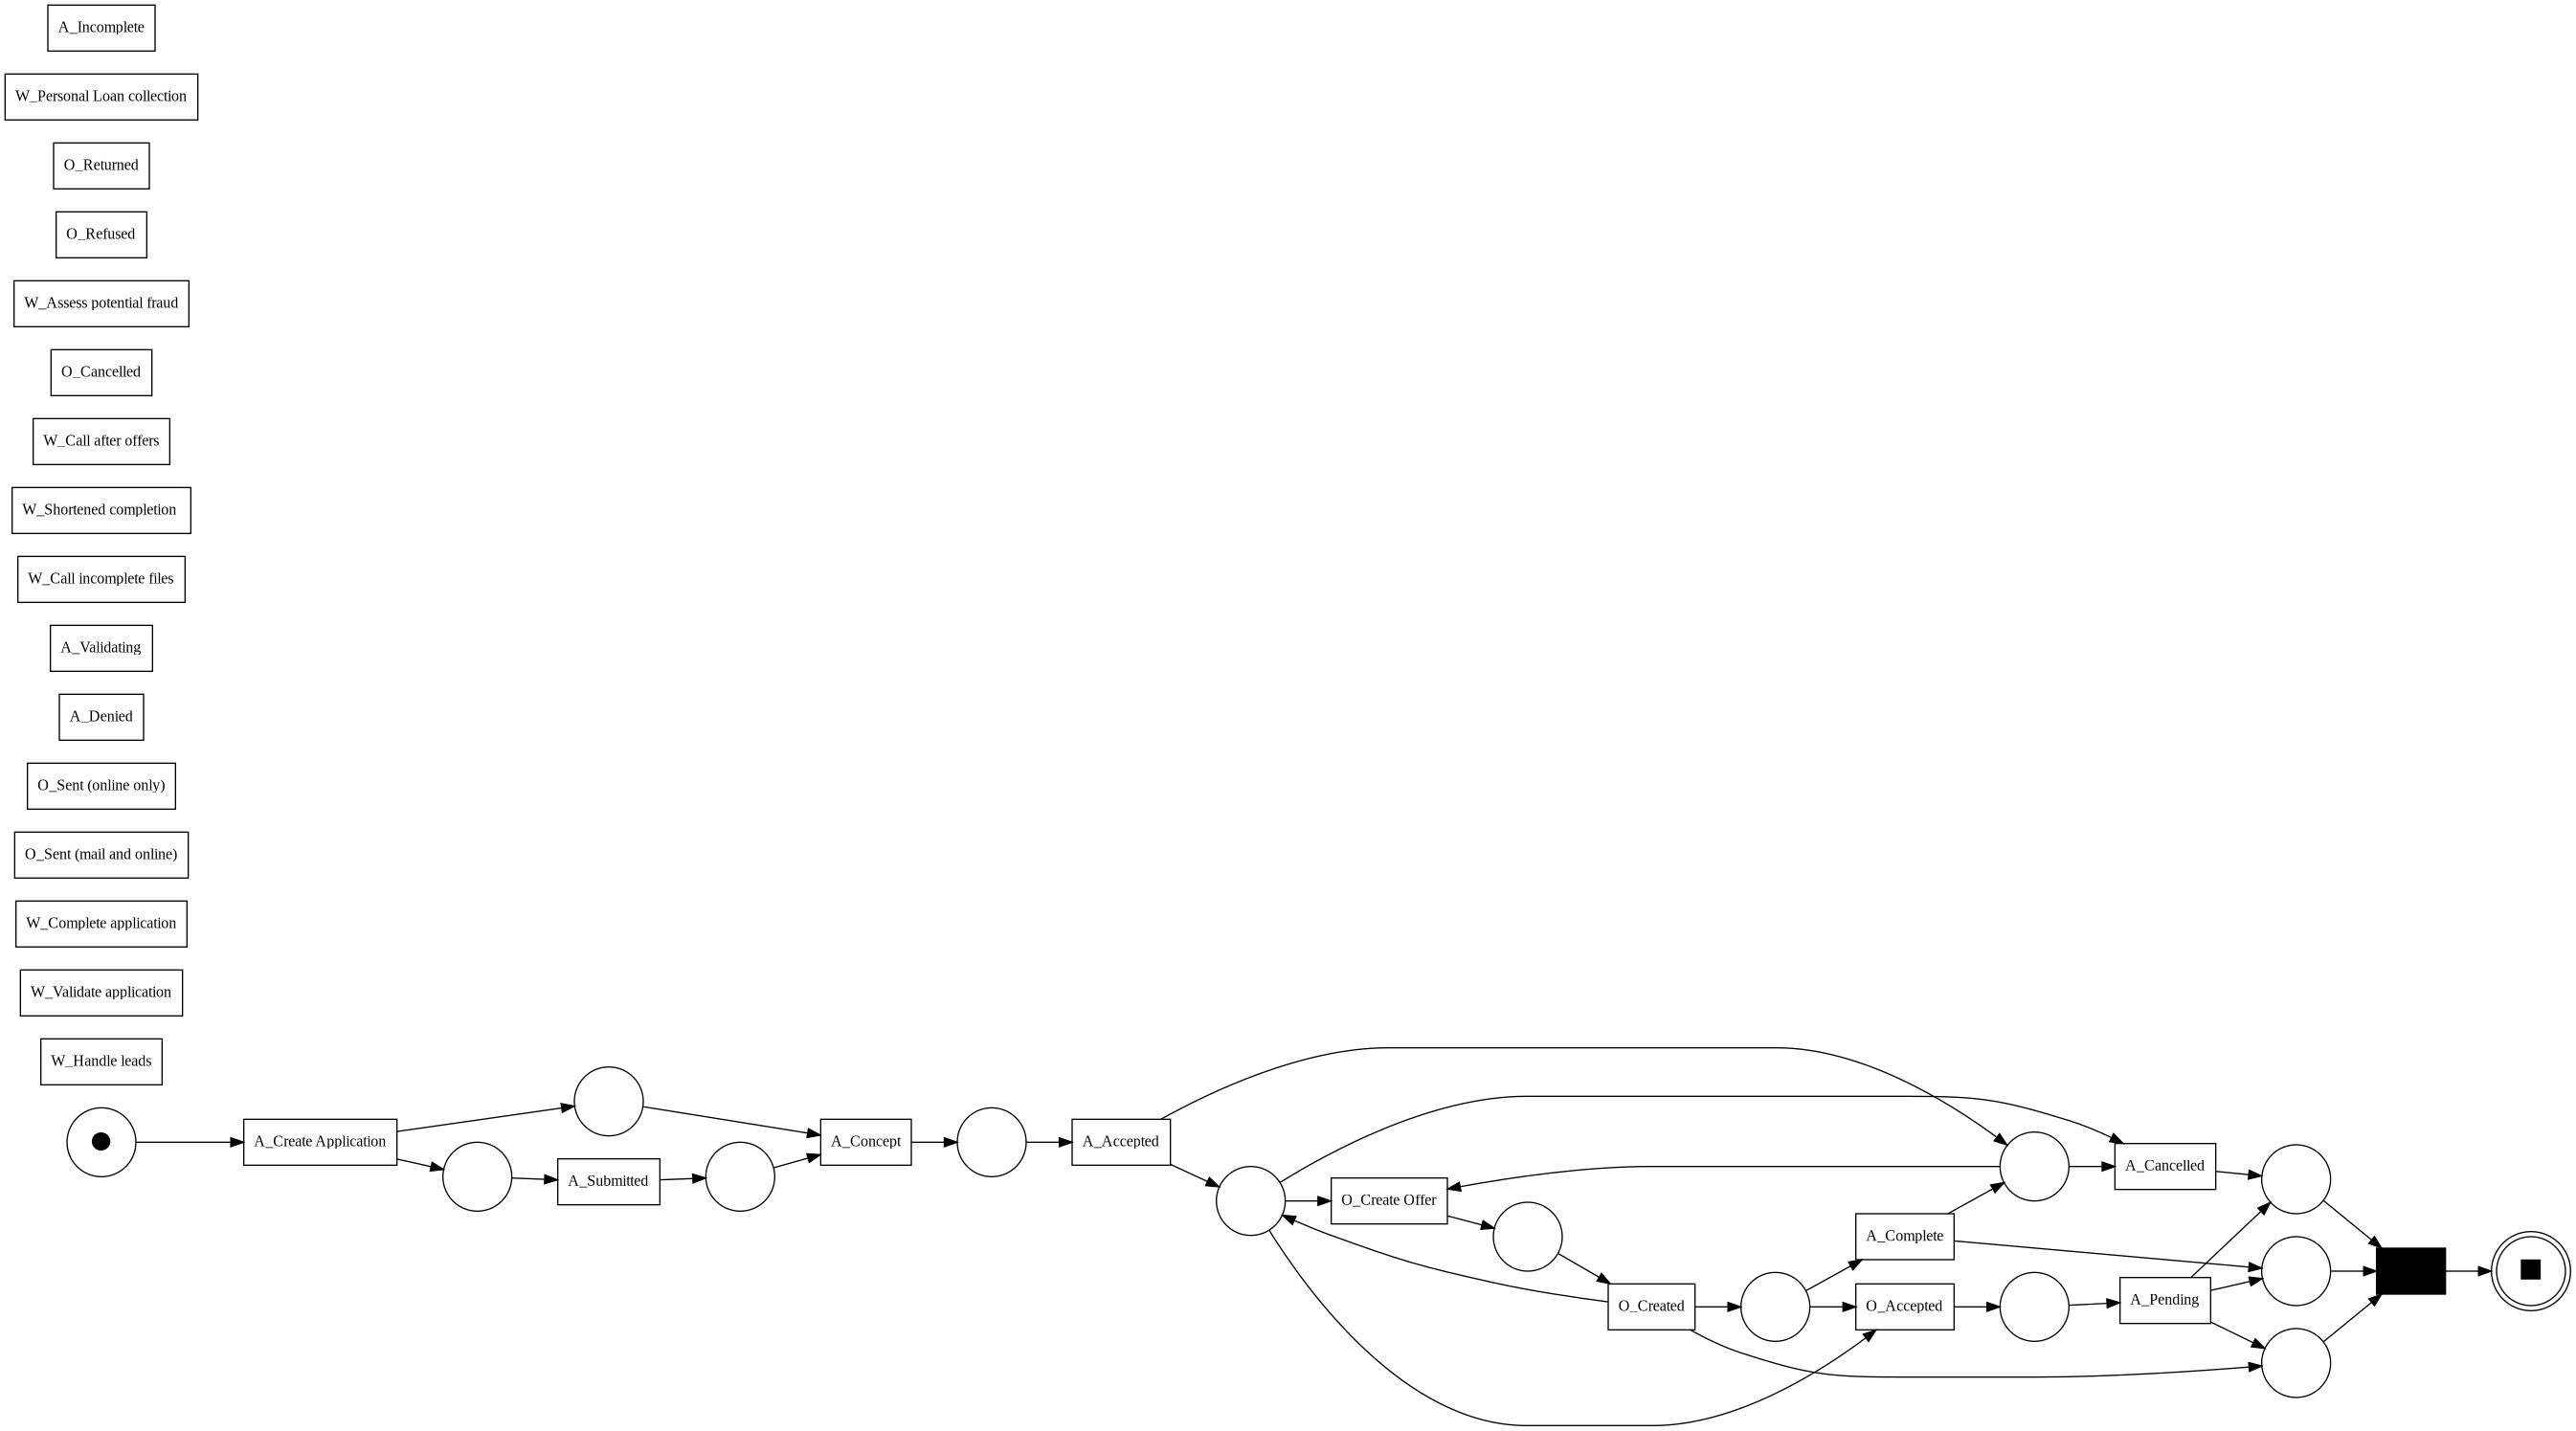

Az Alpha+ Miner ebben a PM4Py-verzióban nem futtatható: name 'extra_models' is not defined


In [40]:
# Alpha+ Miner – opcionális, mert a PM4Py API-ban deprecated.
try:
    net_alpha_plus, im_alpha_plus, fm_alpha_plus = pm4py.discover_petri_net_alpha_plus(log)
    pm4py.view_petri_net(net_alpha_plus, im_alpha_plus, fm_alpha_plus)
    extra_models["Alpha+ Miner"] = (net_alpha_plus, im_alpha_plus, fm_alpha_plus)
except Exception as e:
    print("Az Alpha+ Miner ebben a PM4Py-verzióban nem futtatható:", e)


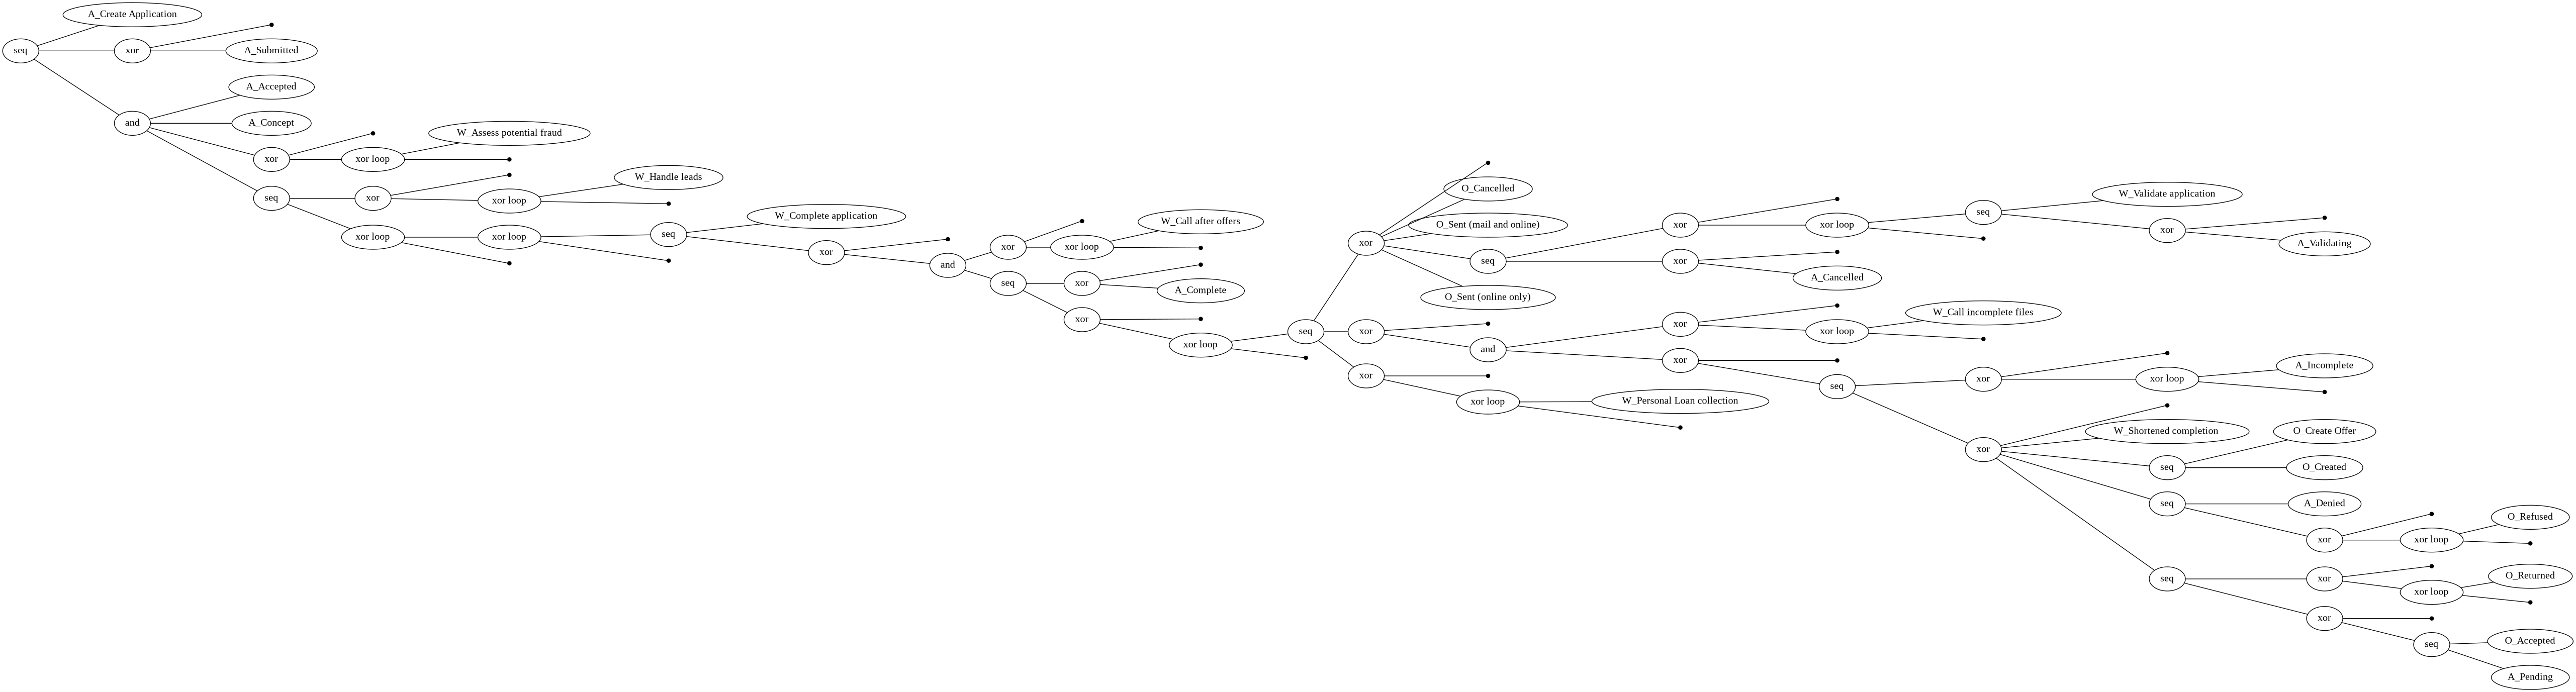

In [42]:
tree = pm4py.discover_process_tree_inductive(log)
pm4py.view_process_tree(tree)

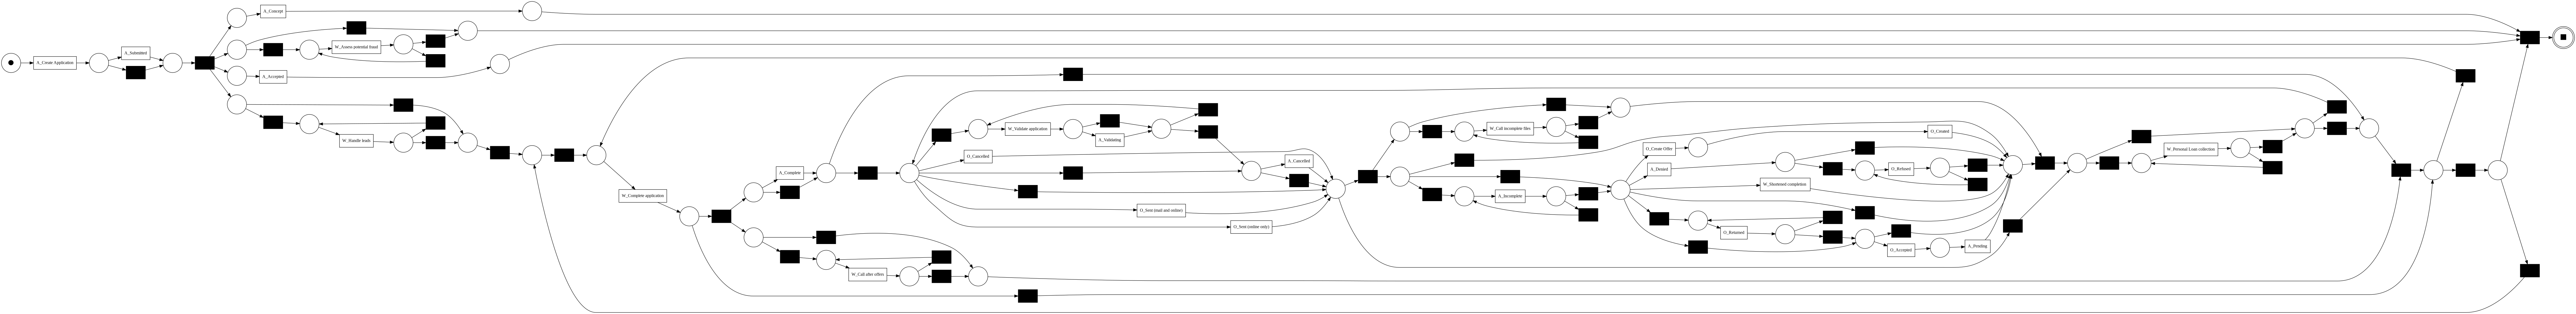

In [43]:
net_ind, im_ind, fm_ind = pm4py.discover_petri_net_inductive(log)

pm4py.view_petri_net(
    net_ind,
    im_ind,
    fm_ind
)

In [ ]:
bpmn_ind = pm4py.discover_bpmn_inductive(log)
pm4py.view_bpmn(bpmn_ind)